# Wine Quality (Red & White) — Dataset Overview

We will use the following dataset for this assignment: 

**Source:** UCI Machine Learning Repository  
**Original study:** P. Cortez et al., *Modeling wine preferences by data mining from physicochemical properties*, Decision Support Systems (2009).

## Files
- `winequality-red.csv` —  (Portuguese *Vinho Verde* red wine)
- `winequality-white.csv` — (Portuguese *Vinho Verde* white wine)
- Delimiter: **`;`** (semicolon)

Your solution should be created by __modifying the provided template Jupyter notebook (ML_2526_assessment.ipynb file)__.

Your solution .ipynb file only (do not include the two csv files) should be renamed to __“ML_2526_assessment_xxxx.ipynb”__ where xxxx is your __student number__, compressed in a __zip archive of the same name__ and uploaded to Blackboard under __“Assessment 2 Supporting Documentation upload”__.


# Task 1: Dataset Import & Preprocessing
<font color = red> ***Marks : 6***</font>
1. Please __import the two datasets__ using as a delimitter the __`;`__
2. Add a __`wine type`__ and then __combine the two datasets into a new one__
3. __Compute the size__ for the 1) red, 2) white datasets, and for the combined one.
4. __Compute the missing values per feature__ (if any).
5. __Display the seven (7)__ instances encountered first in the combined dataset.
6. __Display__ the __basic statistics__ of the dataset.

In [2]:
import pandas as pd
from nbformat.sign import algorithms
from scipy.spatial.distance import euclidean

#import both datasets
redWine = pd.read_csv("winequality-red.csv",sep=";")
whiteWine = pd.read_csv("winequality-white.csv",sep=";")

redWine['wine_type'] = 'red'
whiteWine['wine_type'] = 'white'


mixedWine = pd.concat([redWine, whiteWine], ignore_index=True)
#check if any white wines exist print("Any white wines:", (mixedWine['wine_type'] == 'white').any()) print("White wine count:", (mixedWine['wine_type'] == 'white').sum())

#print the sizes of the 3 datasets
print(redWine)
print("red-size: ")#1599
print(len(redWine))
print("white-size: ")#4898
print(len(whiteWine))
print("combined-size: ")#6497
print(len(mixedWine))

RWC = redWine.isnull().sum()#no missing values in red wine check
WWC = whiteWine.isnull().sum()#no missing values in white wine check

print("\n missing red vals: \n")
print(RWC)
print("\n missing white vals: \n")
print(WWC)

""" indexes-
0: fixed acidity
1: volatile acidity
2: citric acid
3: residual sugar
4: chlorides
5: free sulfur dioxide
6: total sulfur dioxide
7: density
8: pH
9: sulphates
10: alcohol
11: quality
"""

#display the first 7 instances encountered in the data set
print(mixedWine[:7])#print first

print(mixedWine.mean(numeric_only=True))#mean for each numerical value
print(mixedWine.median(numeric_only=True))#median value for each collumn
print(mixedWine.mode(numeric_only=True).iloc[0])#mode per column

Range = mixedWine.describe()
mins = Range.loc["min"]
maxs = Range.loc["max"]
ranges = maxs - mins

widest_feature = ranges.idxmax()
widest_value = ranges.max()
narrowest_feature = ranges.idxmin()
narrowest_value = ranges.min()
print("Widest range:")
print(f"{widest_feature}: {widest_value}")

print("\nNarrowest range:")
print(f"{narrowest_feature}: {narrowest_value}")

display(mixedWine.describe())#print basic statistics



      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               7.4             0.700         0.00             1.9      0.076   
1               7.8             0.880         0.00             2.6      0.098   
2               7.8             0.760         0.04             2.3      0.092   
3              11.2             0.280         0.56             1.9      0.075   
4               7.4             0.700         0.00             1.9      0.076   
...             ...               ...          ...             ...        ...   
1594            6.2             0.600         0.08             2.0      0.090   
1595            5.9             0.550         0.10             2.2      0.062   
1596            6.3             0.510         0.13             2.3      0.076   
1597            5.9             0.645         0.12             2.0      0.075   
1598            6.0             0.310         0.47             3.6      0.067   

      free sulfur dioxide  

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


# Task 1 (Discussion)
<font color = red> ***Marks : 6***</font>
1. Please __mention the main features measured in the dataset__ (not just mention the column names but try to understand their meaning).
2. Are all the features __numerical__? If not, which ones are __categorical__?
3. Check the __summary statistics__ and mention the features having the __widest__ and the __narrowest range of values__.
4. How many __samples (rows)__ are there for __red__ and __white__ wines __separately__ and __combined__?
5. How many __unique quality classes__ exist in the dataset? Are they __evenly spaced__?
6. Is there any __class imbalance__? Which __quality__ value appears the __most__ and which the __least__?
7. Does the __distribution of quality scores__ differ between __red__ and __white__ wines? Can you explain why this might happen from a __real-world perspective__?

# Task 1D (Answer Cell)
1. it measures 11 properties and a qaulity score and wine type, they represent non volatile acides, the measure of acetic acid levels that cause a vinegary taste,  citric acids that add freshness, residual sugar indicates sweetness post fermentation, chlorides reflect salt content, free and total sulfure dioxide act as ppresevatives, density relates alcohol and sugar mass, ph indicates its acidity, sulphates contribute to antimicrobial properties, and alcohol is the percentage by volume, qaulity is the sensory score from a 3-9 rated by experts and wine type distinguishes between red and white wines.
2.   the numerical features are fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH, sulphates and alcohol. quality and wine type are catagorical(red or white, 3456789). There are no missing values in either data set. the numerical values are typically either float64 or int 64 in the case of qaulity.
3.  the widest range is from the sulfur dioxide with a range of 6 - 289g/l across wines, reflecting higher preservation needs in white wines.  the narrowest range in is density with ranges from 0.99-1.00g/cm^3, other ranges include ( Fixed acidity - 4.6 - 15.9, alcohol 8.4 - 14.9 and ph 1.74 - 4.01)
4. red: 1599 white: 4898 combined: 6497 using len() function
5. there are 7 unique values, (3,4,5,6,7,8,9) evenly spaced by 1 on a consistent ordinal scale from poor to excellent,
6. yes there is a class imabalance with a mode of 6 the qaulity 6 occured the most frequently across both sets, followed by 5. with ultra-high qaulities 9 being the rarest
7. white wines show broader qaulity spread with more high (8-9) and low (3-4) scores, peaking at 6, while reds average more commonly at 5-6 with fewer extremes on either end of the scale, this occurs because whites often use more sulfure dioxide for preservation allowing qaulity variation during production unlike reds which need to age.

# Task 2: Dataset Visualization
<font color = red> ***Marks : 7***</font>
1. __Import__ the libraries you need for __numerical__ and __plotting__ tasks (Please ensure that the combined dataset contains the wine_type and the quality).
2. __Create two separate arrays__: one for __red__ wine __quality scores__ and one for __white__. This is essential to __plot them side by side__ for comparison.
3. __Plot the frequency distribution__ of the target variable (quality type) and __report basic statistics__ such as 1) __minimum__, 2) __maximum__, 3) __mean__, 4) __median__, and 5) __mode__.
4. __Define integer-centered bins__. Use __bin edges__ at __`score-0.5`__ and __`score+0.5`__ to align bars correctly. Also set x-axis tick positions for __clarity__.
5. Then __normalize counts to percentages__ so as to make fair comparisons among the red and wine type.
6. __Precompute a common y-axis scale__ to ensure both subplots use the same maximum y-limit for visual comparability.
7. __Plot__ the two __histograms side by side__.
8. __Annotate__ the bars with their percentage values, __add__ an overall figure title and display the result.

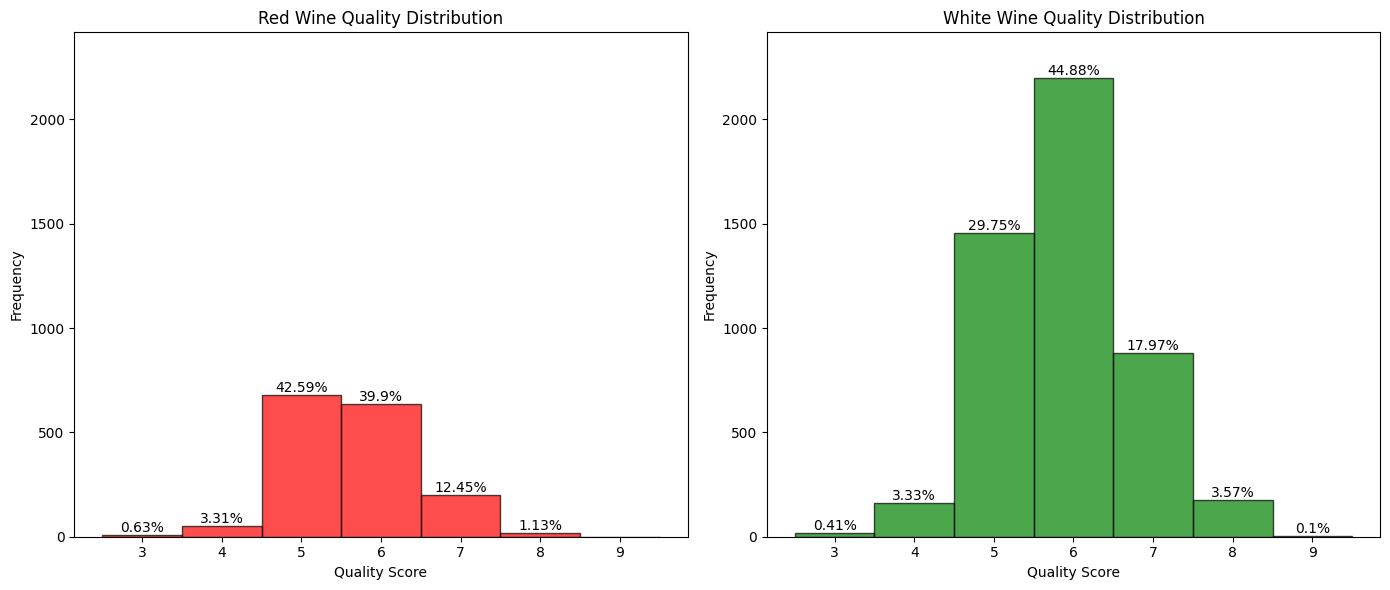

White Minimum: 3
White Maximum: 9
White Mean: 5.87790935075541
White Median: 6.0
White Mode: 6
red Minimum: 3
red Maximum: 8
red Mean: 5.6360225140712945
red Median: 6.0
red Mode: 5
Red wine quality as percent:
 quality
3     0.63
4     3.31
5    42.59
6    39.90
7    12.45
8     1.13
Name: count, dtype: float64
White wine quality as percent:
 quality
3     0.41
4     3.33
5    29.75
6    44.88
7    17.97
8     3.57
9     0.10
Name: count, dtype: float64


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#import the datasets and add a winetype
redWine = pd.read_csv("winequality-red.csv",sep=";")
redWine['wine_type'] = 'red'

whiteWine = pd.read_csv("winequality-white.csv",sep=";")
whiteWine['wine_type'] = 'white'

#combine the datasets
mixedWine = pd.concat([redWine, whiteWine], ignore_index=True)

#two arrays to handle the quality values
redWineQuality = redWine["quality"].to_numpy()
whiteWineQuality = whiteWine["quality"].to_numpy()

# Frequency distribution plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

#set a common y-axis scale to ensure 1:1 comparison
maxRedFreq = redWine['quality'].value_counts().max()
maxWhiteFreq = whiteWine['quality'].value_counts().max()
common_max_freq = max(maxRedFreq, maxWhiteFreq) * 1.1

# Red wine frequency distribution
redCounts, redBins, redPatches = ax1.hist(redWine['quality'], bins=np.arange(2.5, 10.5, 1), color='red', alpha=0.7, edgecolor='black')
ax1.set_title('Red Wine Quality Distribution')
ax1.set_xlabel('Quality Score')
ax1.set_ylabel('Frequency')
ax1.set_ylim(0, common_max_freq)

redCount = redWine['quality'].value_counts().sort_index()
red_total = len(redWine)
redPercentages = (redCount / red_total * 100).round(2)

# White wine frequency distribution
whiteCounts, whiteBins, whitePatches = ax2.hist(whiteWine['quality'], bins=np.arange(2.5, 10.5, 1), color='green', alpha=0.7, edgecolor='black')
ax2.set_title('White Wine Quality Distribution')
ax2.set_xlabel('Quality Score')
ax2.set_ylabel('Frequency')
ax2.set_ylim(0, common_max_freq)

whiteCount = whiteWine['quality'].value_counts().sort_index()
white_total = len(whiteWine)
whitePercentages = (whiteCount / white_total * 100).round(2)

#a function that places a text label of the percentage to 2 nearest decimals
def annotate_bars(ax, patches, percentages):
    for i, patch in enumerate(patches):
        height = patch.get_height()
        if height > 0:
            quality_score = int(patch.get_x() + patch.get_width()/2)
            if quality_score in percentages.index:
                percentage = percentages[quality_score]
                ax.annotate(f'{percentage}%', (patch.get_x() + patch.get_width()/2, height), ha='center', va='bottom', fontsize=10)

annotate_bars(ax1, redPatches, redPercentages)
annotate_bars(ax2, whitePatches, whitePercentages)

plt.tight_layout()
plt.show()

# print Basic statistics
print("White Minimum:", whiteWine['quality'].min())
print("White Maximum:", whiteWine['quality'].max())
print("White Mean:", whiteWine['quality'].mean())
print("White Median:", whiteWine['quality'].median())
print("White Mode:", whiteWine['quality'].mode()[0])
print("red Minimum:", redWine['quality'].min())
print("red Maximum:", redWine['quality'].max())
print("red Mean:", redWine['quality'].mean())
print("red Median:", redWine['quality'].median())
print("red Mode:", redWine['quality'].mode()[0])

print("Red wine quality as percent:\n", redPercentages)
print("White wine quality as percent:\n", whitePercentages)

# Task 2 (Discussion)
<font color = red> ***Marks : 6***</font>
1. Which __quality score(s) dominate__ for red and which for white?
2. Do the distributions suggest __class imbalance overall__ or __within__ each wine type? Please cite approximate percentages from the bars.
3. At which quality scores do red and white wines __differ__ the most in percentage share?
4. Is there a __systematic shift__ (e.g. higher or lower skewness for a specific wine type)? What might explain it?
5. Given the observed class proportions, which __evaluation metrics__ would you __prioritize__ for a classifier (and why)?

# Task 2D (Answer Cell)
1. 5 for red at 42.59% and 6 for white at 44.88%
2. yes there is an imbalance with qualities 5 and 6 being the dominant classes making up roughly 82% (42.59 + 39.90) of the red dataset and 75% (44.88 + 29.75) of the white data set making up roughly 80% across both datasetes with the extreme higher and lower qualities representing the minority classes.
3. at quality 5 the largest difference with reds at 42.59% and whites at 29.75% leaving a gap of 12.84%
4. a systemic shift is present in the quality distributions between the wines. red wine quality shows stronger higher skew towards the peak at score 5 and a longer tail toward higher qualities, white wine shows less skew peaking at 6 with a more even spread across all values. i think this is explained by the fact that red wines take time to age and faces higher expectations for balance and complexity from the tannins/acidity, leading to conservative scoring where white wines benefit from a variance in taste quality and freshness straight after production.
5. The wine quality datasets shows highly imbalanced distributions, with red wine being dominated by qualities 5-6 (82% combined) and extremes like 3 or 8 being under 5%, while white wine also follows a skewed pattern toward mid-range scores 5 and 6 (75% combined).
6. id use F1-score and balance false positives/negatives across the minority classes (such as qualities 3 and 9) to prevent models from trivially predicting the mode 5-6. using AUC-ROC to measure rankings independent of decision thresholds and handle imbalance by avoiding threshold bias (with the majority of classes in 5-6
correct majority guesses dominate the metric despite zero learning)

# Task 3: Implementation
<font color = red> ***Marks : 9***</font>
1. __Create a 4-class label using the rule __`low-quality ≤ 5`__, __`high-quality ≥ 6`__ to define the following classes: __red_low__, __red_high__, __white_low__, __white_high__.
2. Show the value counts and percentages for the four classes.
3. Compute the imbalance ratio as follows: __`max_class_count / min_class_count`__.
4. Define your train/test sets and show per-class counts in each set. Please also verify that all classes are represented in each set.
5. Establish the most appropriate evaluation strategy. This should be coded as a function with no return argument as follows: __`def evaluation_strategy():`__

In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score
from sklearn.metrics import f1_score, precision_score, recall_score

#import the datasets and add a winetype
redWine = pd.read_csv("winequality-red.csv",sep=";")
redWine['wine_type'] = 'red'

whiteWine = pd.read_csv("winequality-white.csv",sep=";")
whiteWine['wine_type'] = 'white'

#combine the datasets
mixedWine = pd.concat([redWine, whiteWine], ignore_index=True)

def classify_quality(row):
    if row['quality'] <= 5:
        qualityScore = 'low'

    elif row['quality'] >= 6:
        qualityScore = 'high'

    else:
        return 0

    return f"{row['wine_type']}_{qualityScore}"

mixedWine['wineClass'] = mixedWine.apply(classify_quality, axis=1)
classCounts = mixedWine['wineClass'].value_counts()
classPercentages = mixedWine['wineClass'].value_counts(normalize=True) * 100

classDistribution = pd.DataFrame({
    'Count': classCounts,
    'Percentage': classPercentages
})

print("Class Distribution:")
print(classDistribution)

maxClassCount = classCounts.max()
minClassCount = classCounts.min()
balanceRatio = maxClassCount / minClassCount
print("maxClassCount: ")
print(maxClassCount)
print("minClassCount: ")
print(minClassCount)
print("balanceRatio: ")
print(balanceRatio)

#remove unimportant data
X = mixedWine.drop(['wineClass', 'quality', 'wine_type'], axis=1)

#choose prediction
y = mixedWine['wineClass']

#split the classes into training and testing sets
xTrain, xTest, yTrain, yTest = train_test_split(X, y,
test_size=0.2,#choose in tens the percentage that goes to testing
random_state=42,#sets a seed for reproducibility
stratify=y)# for unbalanced data: makes all 4 classes appear in both training and testing sets in the same proportions as the original dataset.

print(yTrain.value_counts().sort_index())
print(f"\nTotal training samples: {len(yTrain)}\n")

print(f"All classes represented in both sets: {set(yTrain.unique()) == set(yTest.unique())}")


#the strategy is for a multiclass classification that is no balanced
def evaluation_strategy(yTrue, yPredict):
    # Build your evaluation strategy here

    print(classification_report(yTrue, yPredict))
    print(confusion_matrix(yTrue, yPredict))

    #to fix the imbalance by averaging recalls for each class
    balancedAccuracy = balanced_accuracy_score(yTrue, yPredict)
    print(f"Balanced Accuracy: {balancedAccuracy:}")

    #to treat all classes equally regardless of size
    macro_f1 = f1_score(yTrue, yPredict, average='macro')


    macroPrecision = precision_score(yTrue, yPredict, average='macro')
    macroRecall = recall_score(yTrue, yPredict, average='macro')

    print(f"Macro F1-Score: {macro_f1}")
    print(f"Macro Precision: {macroPrecision}")
    print(f"Macro Recall: {macroRecall}")

    #shows classes with more values as contributing more for comparison with non weighter samples
    weighted_f1 = f1_score(yTrue, yPredict, average='weighted')
    print(f"Weighted F1-Score: {weighted_f1}")

print("\nRecommended evaluation strategy: Primary metric: use macro F1-Scores to treat all wine classes equally\n"
        "Secondary metric: use balanced accuracy to account for class imbalance)\n"
        "Use a confusion matrix to locate specific misclassification patterns\n"
        "Compare Weighted vs Macro F1 to detect minority class issues")


Class Distribution:
            Count  Percentage
wineClass                    
white_high   3258   50.146221
white_low    1640   25.242420
red_high      855   13.159920
red_low       744   11.451439
maxClassCount: 
3258
minClassCount: 
744
balanceRatio: 
4.379032258064516
wineClass
red_high       684
red_low        595
white_high    2606
white_low     1312
Name: count, dtype: int64

Total training samples: 5197

All classes represented in both sets: True

Recommended evaluation strategy: Primary metric: Balanced Accuracy to account for class imbalance)
Secondary metric: use macro F1-Scores to treat all wine classes equally
Use a confusion matrix to locate specific misclassification patterns
Compare Weighted vs Macro F1 to detect minority class issues


# Task 3 (Discussion)
<font color = red> ***Marks : 7***</font>
1. What kind of __data leakage__ would occur if we kept __quality__ in the __`X`__ set?
2. Did you use __stratification__ during the __train_test_split__? Please __justify__ your choice.
3. What __risks__ might arise in __model evaluation__ if some __folds lack a class__ entirely?
4. __Justify__ the decisions made regarding the __evaluation strategy__. How can you prove that is a) __fair__, b) __reproducible__, c) __free from leakage__, d) __robust to class imbalance__?

# Task 3D (Answer Cell)
1. target leakage would occur if the quality remained in the x set since the target variable wineClass is directly derived from the quality column using the classify_quality function, if we kept quality in the set the model would provide a near perfect prediction through knowing the answer before making predictions leading to high training accuracy but poor generalisation to real world data.
2. yes i used stratification in my train_test_split, because the dataset shows a class imbalance and stratification ensures each class appears in training and testing sets in the same proportions as the original unbalanced dataset, without stratification random splitting could create sets with disproportionate class representations making the model biased and for multiclass inbalanced problems stratified splitting prevents minority classes from being underused.
3. if cross validation folds lack a class entirely then classification metrics cannot be computed for absent classes, causing errors and undefined values, the model wont learn patterns for missing classes during training resulting in 0 effect on those classes in test folds.
4. a) the strategy uses balanced accuracy and macro-averaged metrics (F1,Precision,recall) which treat all four wine classes equally regardless of sample sizes, so it does not simply predict the majority class b) the strategy sets a seed in train_test_split to ensure identical data splits across multiple runs. the deterministic nature of the metrics indicates that consistent results will be obtained from an identical input c)excluding quality,wine_type and wineClass from the set guarantees that no target information leaks, the train_test_split should occur before any model training to prevent test data influencing the model. d) the multi metric approach directly addresses imbalance by averaging recalls across classes preventing majority dominant classes, making weighting in each class equal, providing a comparison to see the underperforming classes a confusion matrix to reveal specific misclassification patterns between classes and stratified splitting maintains class proportions in datasets

# Task 4: Implementation
<font color = red> ***Marks : 10***</font>
1. __Set up__ a __logistic regression__ classifier.
2. Use the __`evaluation_strategy()`__ function to __report__ your results

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import numpy as np

#scaler object
scaler = StandardScaler()

#fit on training data, use fit_transform to lean the mean and std from xTrain
xTrainScaled = scaler.fit_transform(xTrain)

#transform the TEST data using the training mean and standard deviation to prevent data leakage
xTestScaled = scaler.transform(xTest)

#logistic regression model
logReg = LogisticRegression(max_iter=1000, random_state=42, solver='lbfgs', class_weight='balanced' )

#train model
logReg.fit(xTrainScaled, yTrain)

#make predictions
yPred = logReg.predict(xTestScaled)

#show
print("=== Logistic Regression Evaluation ===\n")
evaluation_strategy(yTest, yPred)


=== Logistic Regression Evaluation ===

              precision    recall  f1-score   support

    red_high       0.77      0.73      0.74       171
     red_low       0.72      0.77      0.74       149
  white_high       0.84      0.69      0.76       652
   white_low       0.55      0.74      0.63       328

    accuracy                           0.72      1300
   macro avg       0.72      0.73      0.72      1300
weighted avg       0.74      0.72      0.72      1300

[[124  42   5   0]
 [ 34 115   0   0]
 [  3   0 452 197]
 [  1   3  80 244]]
Balanced Accuracy: 0.7335
Macro F1-Score: 0.7209936167196785
Macro Precision: 0.719795825556583
Macro Recall: 0.7335280630335108
Weighted F1-Score: 0.7247081180766632


# Task 4 (Discussion)
<font color = red> ***Marks : 7***</font>
1. __Discuss__ the results and __justify__ the <font color = green> __pros__ </font> and <font color = red> __cons__ </font> of your methodology
2. __Provide insight__ on how these results can be __improved__.

# Task 4D (Answer Cell)
0. the logistic regression classifier I used achieved a balanced accuracy of 73.35% on the test set, the macro f1 score achieved 72.1% and the weighted f1 score was 72.5% which demonstrates a reasonable performance across all class types despite the large (3.38:1) class imbalance with only 8 total cross-wine-type errors with most errors within same wine type.

0. when predicting red high the model is right 77% of the time and finds 73% of actual high quality red wines
0. when red low the model has 72% prediction accuracy and finds 77% of the low quality red wines
0. white high wines were predicted with an 84% accuracy but was overconfident and only found 69% of the high quality whites missing 31%
0. low quality white wines were my major weakness with lots of false positives, it predicted white low too often

The model made 372 errors out of 1,300 test samples (28.6% error rate). 53% of those errors were white high wines being misclassified as white low.


1. strengths -
1. strong wine type discrimination as the model very rarely confused red wines with white wines, showing that chemical values create a clear linear boundary.
1. class_weight = 'balanced' was effective in dealing with the class imbalance achieving roughly 69-77% recall across all classes
1. high quality white wines were identified with a precision of 84% making it reliable for finding premium white wines.

2. weaknesses -
2. most of the errors occurred between quality levels of the same wine type indicating that the model struggles with subtle differences in quality (197 white_high samples misclassified as white_low)
2. many white wines (nearly half) were incorrectly predicted as white low indicating the model is conservative in predicting high quality whites due to its over prediction of low quality whites
2. the model assumes linear relationships between chemical properties and quality, ignoring potential non-linear interactions.

3. improvements -
3. polynomial features (I couldn't get multi_class='multinomial' to work even with latest scikit version.) add degree-2 polynomial terms to capture interactions like alcohol x volotile acidicty which likely effect on quality non-linearly
3. create a domain-specific feature that wine experts would consider (such as acidity ratios or sweetness to alcohol level)
3. threshold tuning adjust decision thresholds for white_low to improve its mediocre 55% precision withouth sacrificing too much recall
4. compare with a more advanced model with non-linear classifiers to capture complex patterns logistic regression models cannot handle.

5. in summary the logistic regression model provides fast interperatble data with strong discrimination, its linear nature however seems to limit its performance when predicting subtle changes in quality.

# Task 5: Implementation
<font color = red> ***Marks : 11***</font>
1. In this task you have to __train__ and __compare three `scikit-learn` classifiers__ on the __4-class dataset__ previously created.
2. All three classifiers should allow __hyperparameter tuning__.
3. To do so, it is __strongly suggested__ to use a __train/validation/test__ workflow.
4. You are __strongly advised__ <font color = red> __not to use__ a __random forest__ classifier.

In [15]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, balanced_accuracy_score,f1_score,precision_score,recall_score

#==========================================================#from question 3
def classify_quality(row):
    if row['quality'] <= 5:
        qualityScore = 'low'
    elif row['quality'] >= 6:
        qualityScore = 'high'
    else:
        return 0
    return f"{row['wine_type']}_{qualityScore}"

def evaluation_strategy(yTrue, yPredict):
    print(classification_report(yTrue, yPredict))
    print(confusion_matrix(yTrue, yPredict))
    balancedAccuracy = balanced_accuracy_score(yTrue, yPredict)
    print(f"Balanced Accuracy: {balancedAccuracy:}")
    macro_f1 = f1_score(yTrue, yPredict, average='macro')
    macroPrecision = precision_score(yTrue, yPredict, average='macro')
    macroRecall = recall_score(yTrue, yPredict, average='macro')
    print(f"Macro F1-Score: {macro_f1}")
    print(f"Macro Precision: {macroPrecision}")
    print(f"Macro Recall: {macroRecall}")
    weighted_f1 = f1_score(yTrue, yPredict, average='weighted')
    print(f"Weighted F1-Score: {weighted_f1}")

mixedWine['wineClass'] = mixedWine.apply(classify_quality, axis=1)
#=============================================================#
# keep only 11 chem properties
X = mixedWine.drop(['quality','wine_type','wineClass'], axis=1).copy()

Y = mixedWine['wineClass']

#print("Features X:"), print(X.shape), print(list(X.columns)), print("\nTarget Y:"), print(Y.shape), print(sorted(Y.unique())), print("\nClass distribution:"), print(Y.value_counts().sort_index())

xTrainFull, xTest, yTrainFull, yTest = train_test_split(
    X, Y,
    test_size=0.2, #choose in tens the percentage that goes to testing
    random_state=42, #sets a seed for reproducibility
    stratify=Y  # for unbalanced data: makes all 4 classes appear in both training and testing sets in the same proportions as the original dataset.
)

#no xTest and Ytest so that the test set remains completely unseen until final evaluation
xTrain, xVal, yTrain, yVal = train_test_split( xTrainFull, yTrainFull,
    test_size=0.25,  # 0.25 x 80% = 20% overall validation
    random_state=42,
    stratify=yTrainFull
)
#print(f"Training set: {len(xTrain)} samples") print(f"Validation set: {len(xVal)} samples") print(f"Test set: {len(xTest)} samples")

scaler = StandardScaler()

xTrainScaled = scaler.fit_transform(xTrain)#fit on training data, use fit_transform to learn the mean and std from xTrain
xValScaled = scaler.transform(xVal)
xTestScaled =  scaler.transform(xTest)

###########################SVC

svcParamGrid = {
    'C': [0.1,1,10,100],#low c is more tolerant of misclassifications
    'gamma': [0.001,0.01,0.1,1],#controls decision boundary / smoothes line, high gamma means wiggly boundaries
    'kernel':['rbf'],#radial basis function for non linear patterns
    'class_weight':['balanced']
}

svcGrid = GridSearchCV(#tests every possible combination of parameters
    SVC(random_state=42),
    param_grid=svcParamGrid,
    cv=5,# will be trained and tested x number of times train on 4 test on 5th then cycle through
    scoring='balanced_accuracy',#calculates seperately then averages
    n_jobs=-1,#use all cpu cores
    verbose=1#show progress
)
svcGrid.fit(xTrainScaled,yTrain)

print(f"best parameters:\n{svcGrid.best_params_}\n")
print(f"best cv score:\n{svcGrid.best_score_}\n")

yPredictionSVC = svcGrid.predict(xValScaled)

print(f"SVC evaluation\n")
evaluation_strategy(yVal,yPredictionSVC)

###########################ADA

adaParamGrid = {
    'n_estimators':[50, 100, 200],#number of weak learners
    'learning_rate':[0.01, 0.1, 0.5, 1.0]#weight of contribution
}

adaGrid = GridSearchCV(
    AdaBoostClassifier(random_state=42),
    param_grid=adaParamGrid,
    cv=5,
    scoring='balanced_accuracy',
    n_jobs=-1,
    verbose=1
)
adaGrid.fit(xTrainScaled, yTrain)

print(f"best parameters:\n{adaGrid.best_params_}\n")
print(f"best cv score:\n{adaGrid.best_score_}\n")

yPredictionADA = adaGrid.predict(xValScaled)

print(f"ADA evaluation\n")
evaluation_strategy(yVal, yPredictionADA)

###########################KNN

knnParamGrid = {
    'n_neighbors': [3, 5, 7, 11, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

knnGrid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid=knnParamGrid,
    cv=5,
    scoring='balanced_accuracy',
    n_jobs=-1,
    verbose=1
)
knnGrid.fit(xTrainScaled, yTrain)

print(f"KNN Best Parameters:\n{knnGrid.best_params_}\n")
print(f"KNN Best CV Score:\n{knnGrid.best_score_}\n")

yPredictionKNN = knnGrid.predict(xValScaled)

print("KNN evaluation")
evaluation_strategy(yVal, yPredictionKNN)

###########################model comparison
results = pd.DataFrame({
    'Model': ['SVC (RBF)', 'AdaBoost', 'KNN'],
    'Validation Accuracy': [
        balanced_accuracy_score(yVal, yPredictionSVC),
        balanced_accuracy_score(yVal, yPredictionADA),
        balanced_accuracy_score(yVal, yPredictionKNN),
    ]
}).sort_values('Validation Accuracy', ascending=False)

print(results)
print(f"\n Best Model: {results.iloc[0]['Model']}")

###########################FINAL TEST COMPARISON
print("FINAL TEST SET EVALUATION (UNSEEN DATA)")

print("SVC Test Set Results:")
yTestSVC = svcGrid.predict(xTestScaled)
evaluation_strategy(yTest, yTestSVC)

print("AdaBoost Test Set Results:")
yTestADA = adaGrid.predict(xTestScaled)
evaluation_strategy(yTest, yTestADA)

print("KNN Test Set Results:")
yTestKNN = knnGrid.predict(xTestScaled)
evaluation_strategy(yTest, yTestKNN)

print("FINAL TEST SET COMPARISON")

test_results = pd.DataFrame({
    'Model': ['SVC (RBF)', 'AdaBoost', 'KNN'],
    'Test Balanced Accuracy': [
        balanced_accuracy_score(yTest, yTestSVC),
        balanced_accuracy_score(yTest, yTestADA),
        balanced_accuracy_score(yTest, yTestKNN)
    ],
    'Test Macro F1': [
        f1_score(yTest, yTestSVC, average='macro'),
        f1_score(yTest, yTestADA, average='macro'),
        f1_score(yTest, yTestKNN, average='macro')
    ]
}).sort_values('Test Balanced Accuracy', ascending=False)

print(test_results)
print(f"\nBest Final Model: {test_results.iloc[0]['Model']}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
best parameters:
{'C': 10, 'class_weight': 'balanced', 'gamma': 0.1, 'kernel': 'rbf'}

best cv score:
0.7538491134539853

SVC evaluation

              precision    recall  f1-score   support

    red_high       0.72      0.69      0.71       171
     red_low       0.66      0.70      0.68       149
  white_high       0.87      0.79      0.83       652
   white_low       0.65      0.77      0.71       328

    accuracy                           0.76      1300
   macro avg       0.73      0.74      0.73      1300
weighted avg       0.77      0.76      0.76      1300

[[118  51   1   1]
 [ 43 105   0   1]
 [  2   2 513 135]
 [  0   1  73 254]]
Balanced Accuracy: 0.738989131490676
Macro F1-Score: 0.7307572579952961
Macro Precision: 0.7269638427999059
Macro Recall: 0.738989131490676
Weighted F1-Score: 0.7646724448758444
Fitting 5 folds for each of 12 candidates, totalling 60 fits
best parameters:
{'learning_rate': 0.5, 'n_estimat

# Task 5 (Discussion)
<font color = red> ***Marks : 9***</font>
1. __Justify__ your choices regarding the __three different__ classifiers.
2. Report __which classifier performed better__, and which had the __poorest performance__. How can you __explain__ their performance?
3. Report the __optimal parameter set__ for each classifier, their __meaning__, and try to __explain__ this result.
4. Given your results, if you could __keep only one__ classifier, which would you choose for <font color = blue> __deployment__ </font> and __why__? Please __justify__ your answer by referring to __interpretability__, __performance__, __stability__, __computational cost__, and __resilience to class imbalance__.
5. Imagine you are presenting your work to a __non-technical stakeholder__: How would you explain why __tuning matters__ and __show evidence__ that it __improved performance__?

# Task 5D (Answer Cell)

# Task 6 (Implementation)
<font color = red> ***Marks : 12***</font>
1. __Build one ensemble classifier__ that <font color = blue> __stacks your three tuned non-ensemble__ </font> models from the previous task.
2. To do so, please use __`scikit-learn`__’s <font color = blue> __StackingClassifier__ </font>.
3. To do so, it is strongly suggested to use a __train/validation/test__ workflow.
4. There is a strong suggestion to use a __Train/Validation/Test__ protocol (no CV for selection here) and __tune key hyperparameters__ on the __Validation__ split and show whether __staking improves your evaluation strategy__ over the best single model.

In [ ]:
# Task 6I (Solution Cell)

# Task 6 (Discussion)
<font color = red> ***Marks : 10***</font>
1. Did the __ensemble outperform__ your __best single__ model or not? __Justify__ your answer by considering __model diversity__, __overfitting__ and __data size__.
2. Why __combining several diverse base__ classifiers may produce __better generalization__ than any __single__ model?
3. How do __ensemble methods__ like __stacking__ reduce __variance__, __bias__ or __both__?
4. Why is __model diversity__ important in ensembles? What would happen if __all base models made similar mistakes__?
5. How can using a __meta-learner__ in __stacking__ <font color = red> __improve the strengths__ </font> of each base model?

# Task 6D (Answer Cell)